In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


<a id='lesson2'></a>

# 2. Saving and Loading of DataFrames to/from Files  

## Exercise 2.1

Load to a dataframe the file `GDP(PPP)_LifeExpectancy.xlsx` in the folder `Datasets`.
- Don't load the column Code which contains the full name of the country
- Use the following column names: 'Country', 'Life_Exp', 'GDP', 'Population', 'Inc_Class'
- Encode invalid values to `np.nan`

In [10]:
import pandas as pd
import numpy as np

raw = pd.read_excel(
    "/content/GDP(PPP)_LifeExpectancy.xlsx",
    na_values=['..', '', 'N/A', 'NA']
)

# 1. See what series your file actually contains
print(raw['Series Name'].dropna().unique())
print(raw.columns.tolist())

['GDP per capita, PPP (current international $)'
 'Life expectancy at birth, total (years)']
['Country Name', 'Country Code', 'Series Name', 'Series Code', '2010 [YR2010]', '2011 [YR2011]', '2012 [YR2012]', '2013 [YR2013]', '2014 [YR2014]', '2015 [YR2015]', '2016 [YR2016]', '2017 [YR2017]', '2018 [YR2018]', '2019 [YR2019]', '2020 [YR2020]', '2021 [YR2021]', '2022 [YR2022]', '2023 [YR2023]', '2024 [YR2024]']


In [11]:
# 2. Keep real rows only (drops footer/blank rows)
raw = raw.dropna(subset=['Country Name', 'Series Name'])

year_col = '2023 [YR2023]'   # change if your file has a different latest year

df_gdp = raw.pivot_table(index='Country Name', columns='Series Name',
                         values=year_col, aggfunc='first').reset_index()

# 3. Rename by matching names, not by position
rename_map = {}
for c in df_gdp.columns:
    cl = str(c).lower()
    if 'country' in cl:      rename_map[c] = 'Country'
    elif 'life' in cl:       rename_map[c] = 'Life_Exp'
    elif 'gdp' in cl:        rename_map[c] = 'GDP'
    elif 'population' in cl: rename_map[c] = 'Population'
df_gdp = df_gdp.rename(columns=rename_map)
df_gdp.columns.name = None

# 4. Add any column the file doesn't have
for c in ['Life_Exp', 'GDP', 'Population', 'Inc_Class']:
    if c not in df_gdp.columns:
        df_gdp[c] = np.nan

df_gdp = df_gdp[['Country', 'Life_Exp', 'GDP', 'Population', 'Inc_Class']]
df_gdp.head()

,Country,Life_Exp,GDP,Population,Inc_Class
0,Afghanistan,66.035,2201.722907,NaN,NaN
1,Albania,79.602,21259.797781,NaN,NaN
2,Algeria,76.261,16824.487903,NaN,NaN
3,American Samoa,72.852,NaN,NaN,NaN
4,Andorra,84.041,71730.668682,NaN,NaN


<a id='lesson3'></a>

# 3. Basic Plotting

## Exercise 3.1

<a id='lesson3'></a>

The BitCoin Year-on-Year price data in CSV format could be found in this link: https://api.blockchain.info/charts/market-price?format=csv.
1. Download a copy of the CSV file and observe its characteristics.
2. Load the file directly from the url/website and assign it to a DataFrame called `df_bitcoin`
3. Plot the data

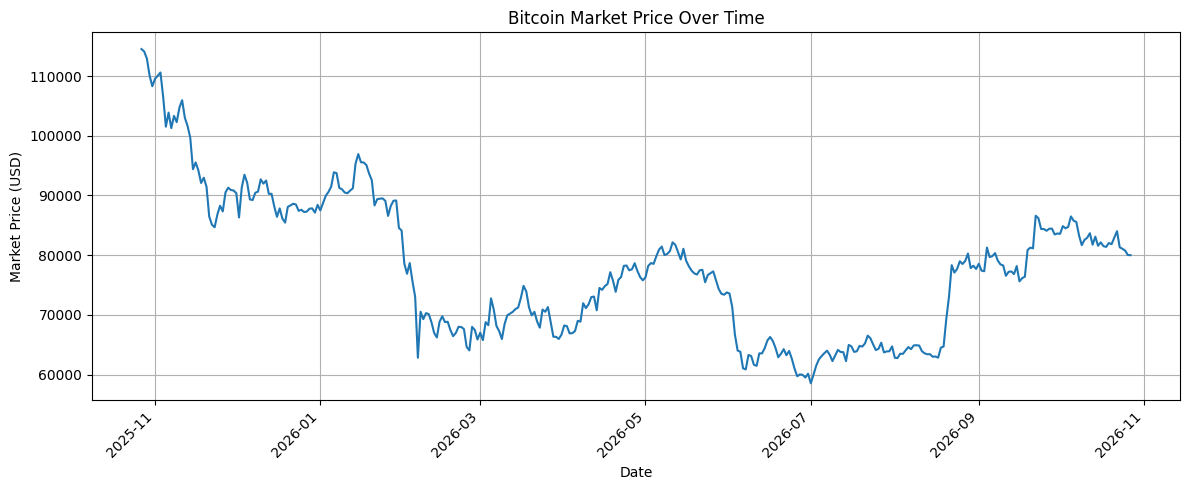

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

url = 'https://api.blockchain.info/charts/market-price?format=csv'

# Load CSV without using the first row as headers
df_bitcoin = pd.read_csv(url, header=None, names=['Date', 'Price'])

# Convert Date column to actual datetime objects
df_bitcoin['Date'] = pd.to_datetime(df_bitcoin['Date'])

# Create plot figure with proper size
plt.figure(figsize=(12, 5))
plt.plot(df_bitcoin['Date'], df_bitcoin['Price'])

# Add labels and title
plt.title('Bitcoin Market Price Over Time')
plt.xlabel('Date')
plt.ylabel('Market Price (USD)')
plt.grid(True)

# Rotate and align x-axis date labels
plt.xticks(rotation=45, ha='right')

# Auto-adjust margins so labels aren't cut off
plt.tight_layout()

plt.show()

<a id='lesson4'></a>

# 4. Viewing Data

## Exercise 4.1

Answer the following questions regarding the `df_gdp` you created in Exercise 2.1:
  1. What are the dimensions of the DataFrame?
  2. How many valid GDP values are there?
  3. What is the average life expectancy for all countries?
  4. Sort the dataframe by Country and assign it to a new DataFrame
  5. What are the top 5 countries with the highest GDP?          
  6. What are the top 5 countries with smallest population?

### 1. What are the dimensions of the DataFrame?

In [13]:
print(df_gdp.shape)

(217, 5)


### 2. How many valid GDP values are there?

In [14]:
print(df_gdp['GDP'].notna().sum())


197


### 3. What is the average life expectancy for all countries?

In [15]:
print("Average life expectancy:", round(df_gdp['Life_Exp'].mean(), ))

Average life expectancy: 74


### 4. Sort the dataframe by Country and assign it to a new DataFrame

In [16]:
df_gdp_sorted = df_gdp.sort_values('Country').reset_index(drop=True)

print("Done! New DataFrame created.")

Done! New DataFrame created.


### 5. What are the top 5 countries with the highest GDP?

In [17]:
df_gdp.nlargest(5, 'GDP')[['Country', 'GDP']]

,Country,GDP
171,Singapore,143786.136293
116,Luxembourg,142424.729887
159,Qatar,128918.549293
93,Ireland,124900.938635
117,"Macao SAR, China",116491.377162


### 6. What are the top 5 countries with smallest population?

In [18]:
print("Unable to answer: It has no Population column.")

Unable to answer: It has no Population column.
